In [1]:
import os, sys
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import coffea.util
import matplotlib.pyplot as plt
import yaml
import awkward as ak

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()
%matplotlib inline

In [2]:
data = functions.get_data_files()
# data_lists = {

#     "data_A": [x for x in data if "A" in x],

#     "data_B": [x for x in data if "B" in x],
#      "data_C": [x for x in data if "C" in x],
#        "data_D": [x for x in data if "D" in x],

# }

channel_name  = "cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu_dxy"


In [3]:
DY= [
      "DYJetsToLL_M10to50",
       "DYJetsToLL_M50",
]
folder_name = f"OutputFiles/{channel_name}"
sum_data_all = utilities.sum_hist(data, folder_name)
summed_DY  = utilities.sum_hist(DY, folder_name)

In [4]:
histogram_list=['cosAlpha_dsa', 'cosAlpha_pf', 'cosAlpha_mu', 'min_cosAlpha_mu', 'min_cosAlpha_pf', 'min_cosAlpha_dsa', 'egm_lj_pt', 'mu_lj_pt', 'mu_lj_muonN', 'mu_lj_pfMu_n', 'mu_lj_dsaMu_n', 'mu_lj_muon_pt', 'mu_lj_pfMuon_pt', 'mu_lj_dsaMuon_pt', 'electron_pt', 'muon_pt', 'dsaMuon_pt', 'mu_lj_vxySpread_pf', 'mu_lj_dxySpread_mu', 'muon_n', 'electron_n', 'dsaMuon_n', 'photon_n', 'photon_pt']

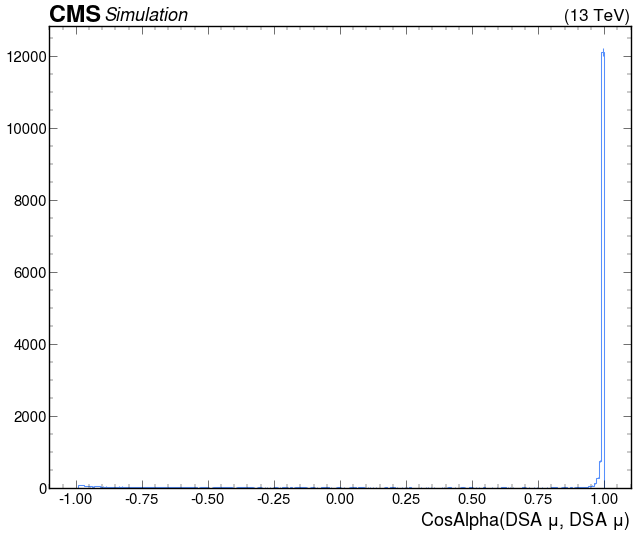

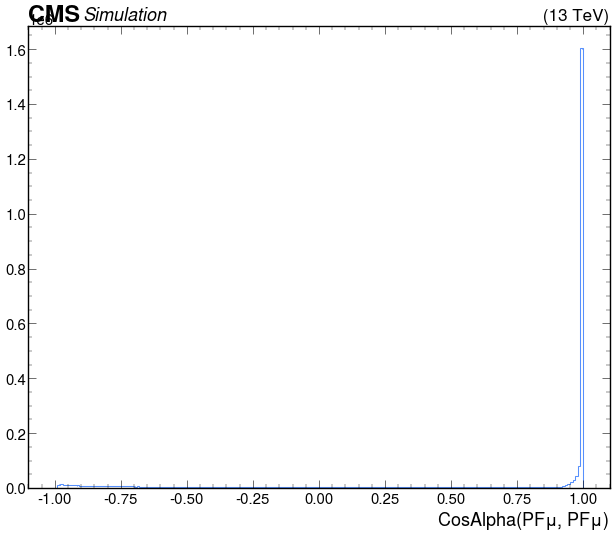

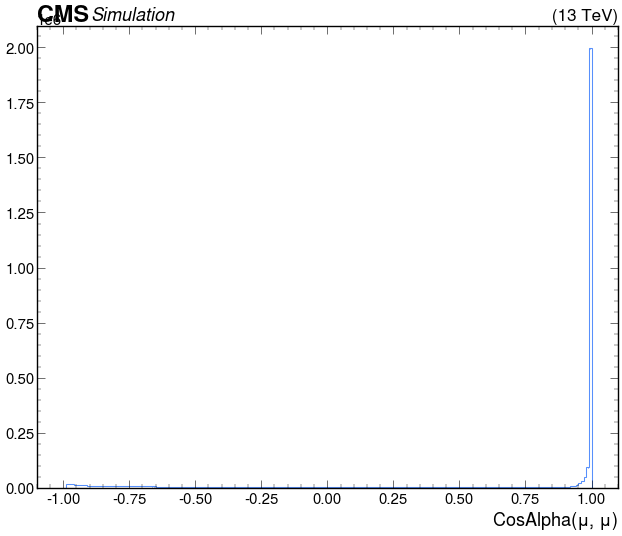

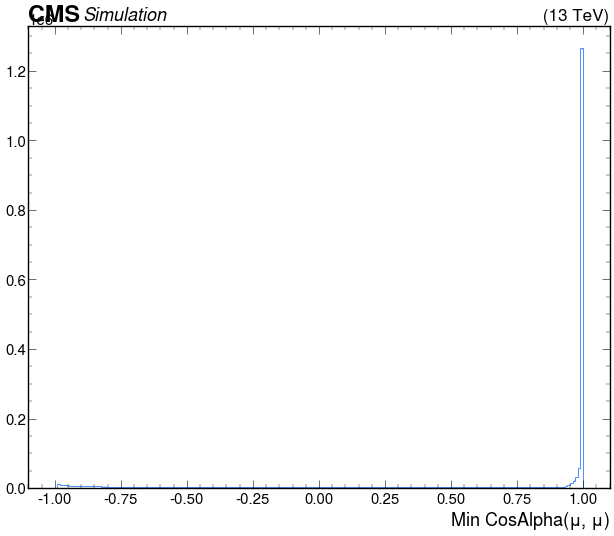

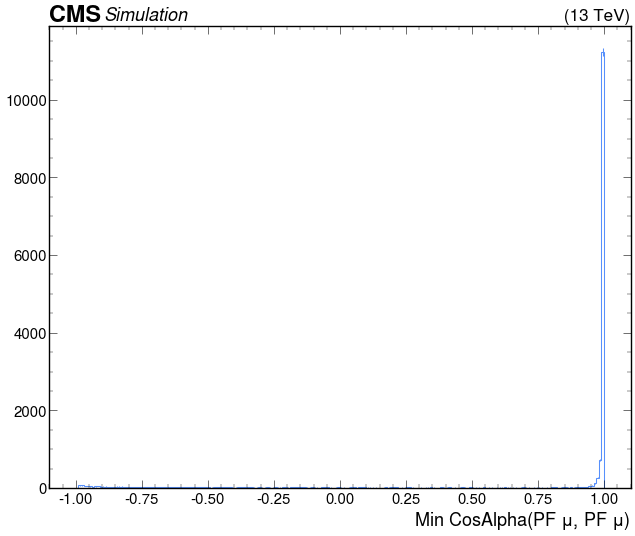

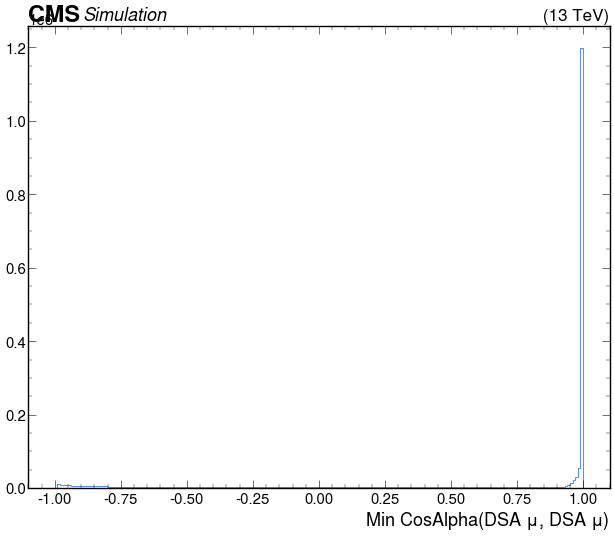

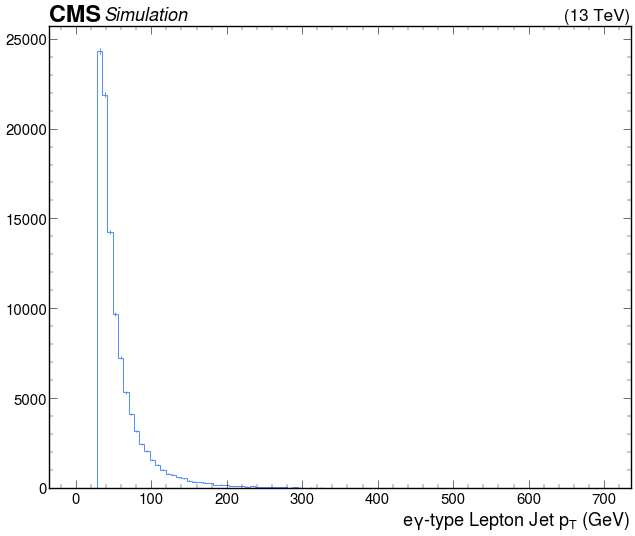

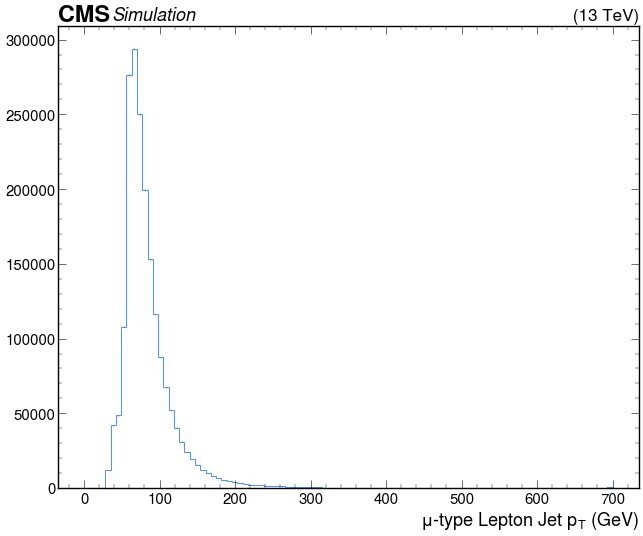

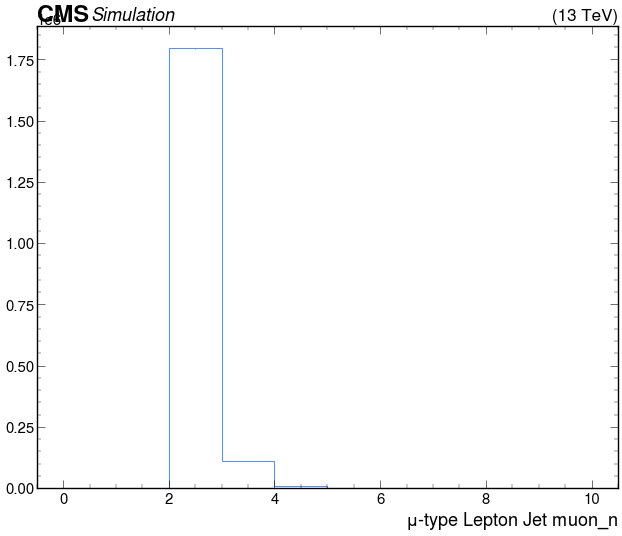

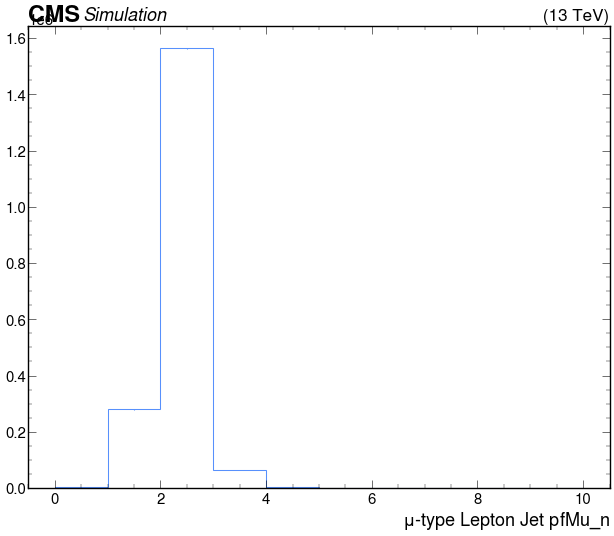

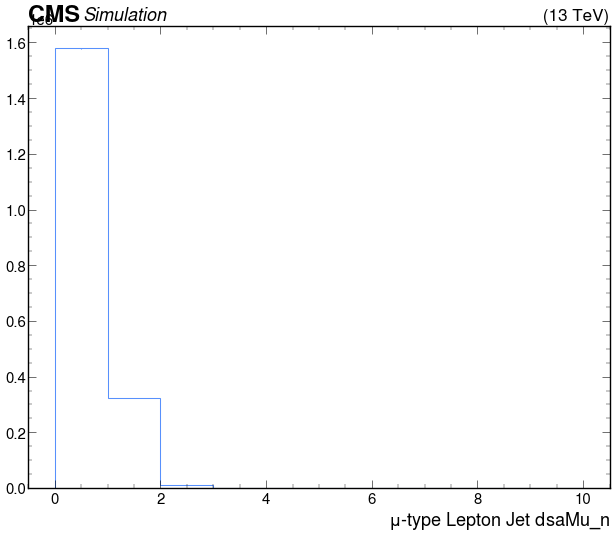

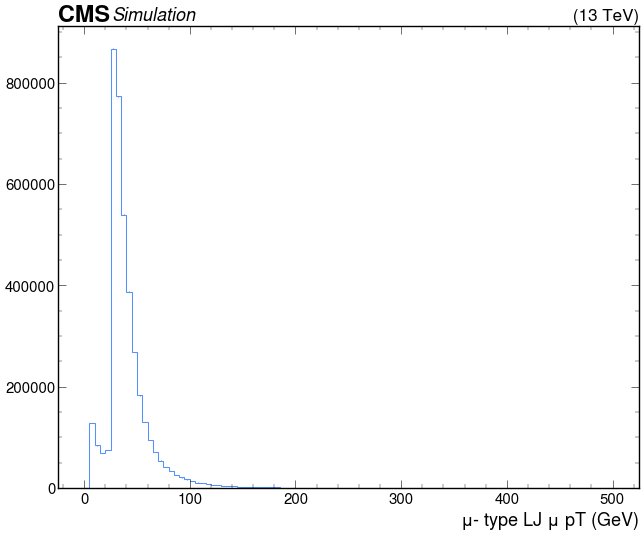

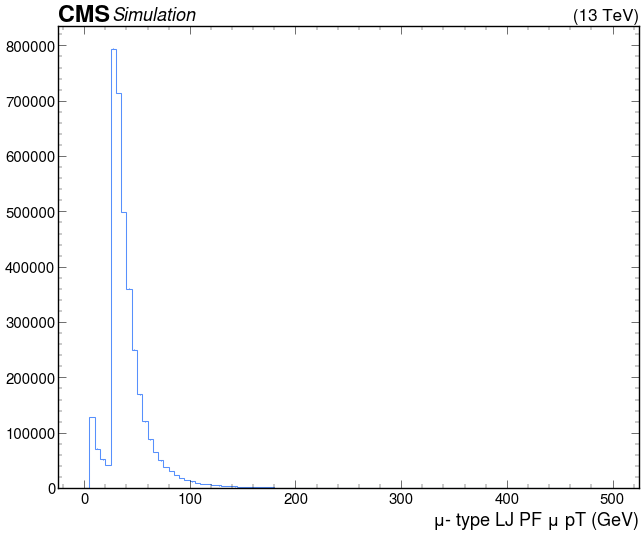

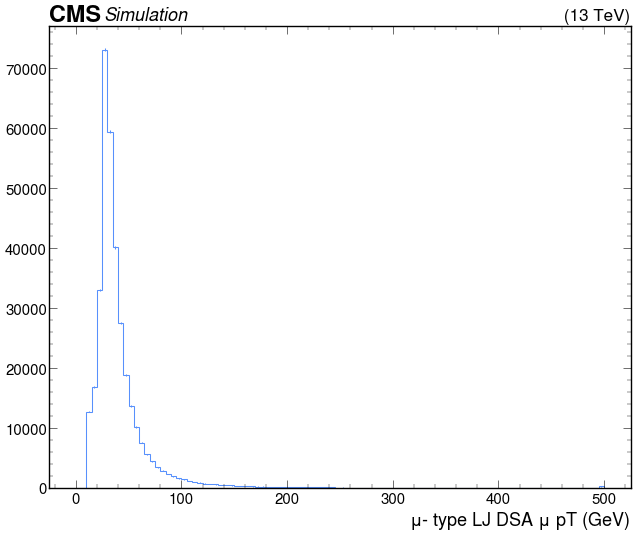

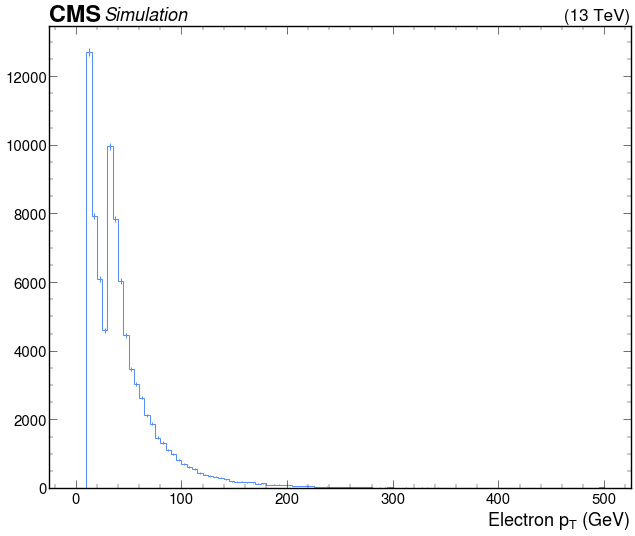

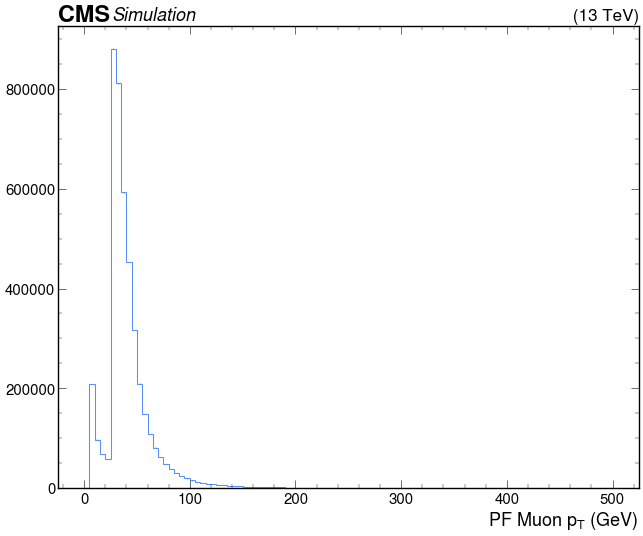

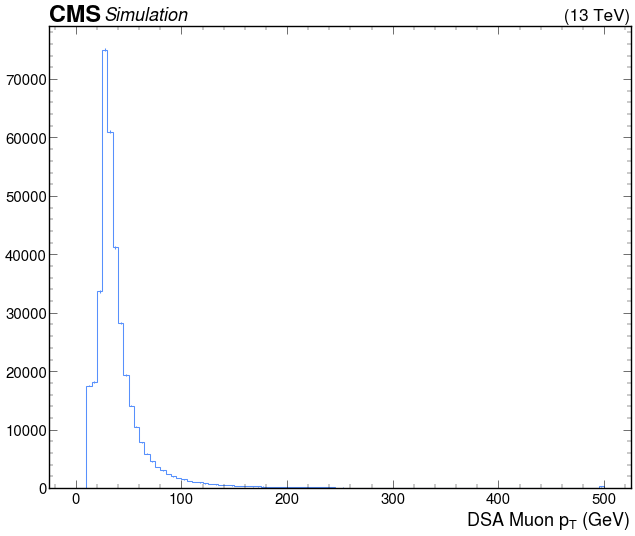

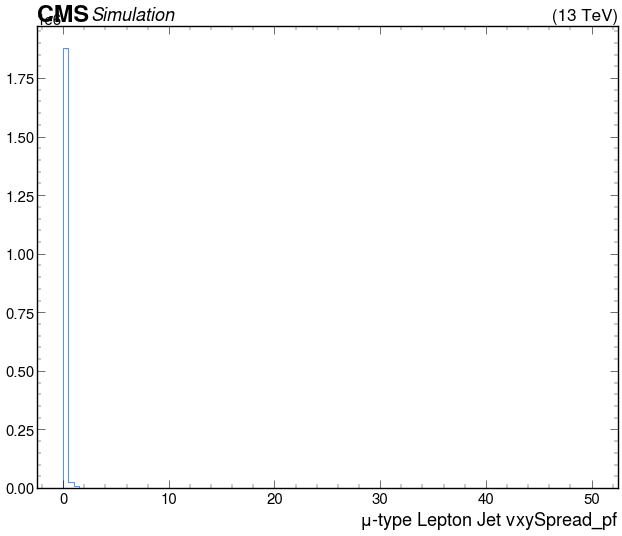

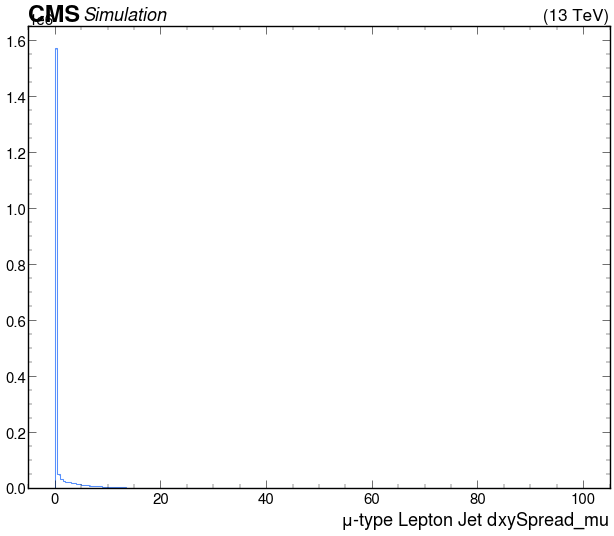

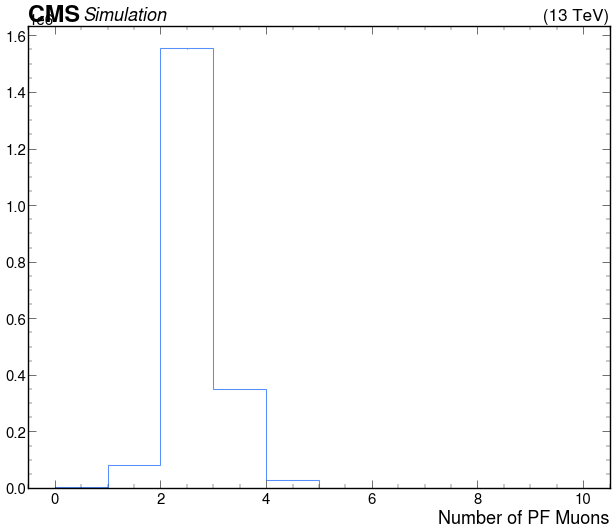

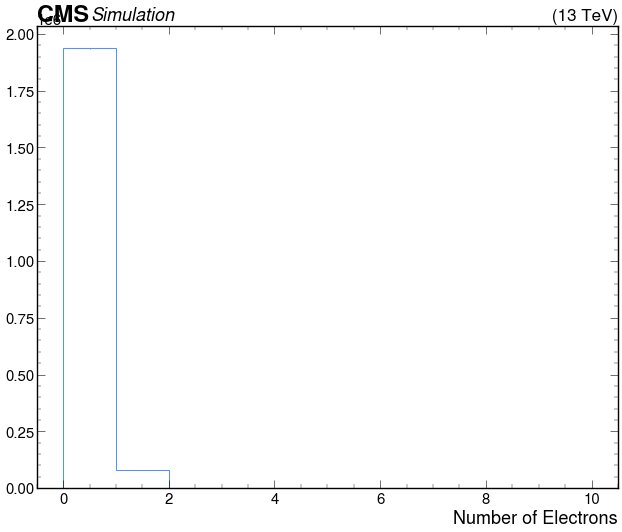

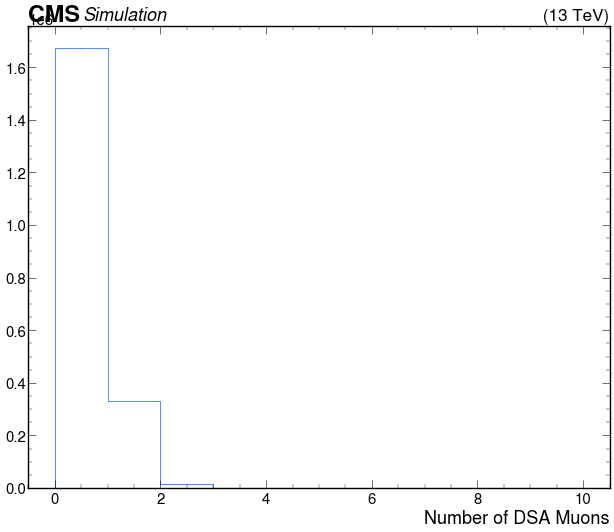

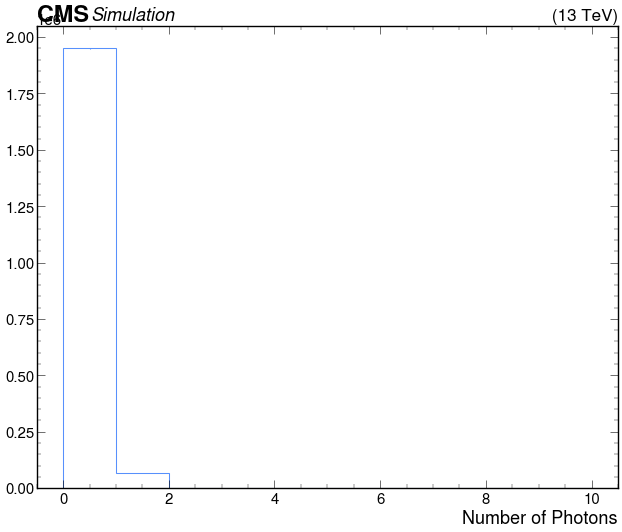

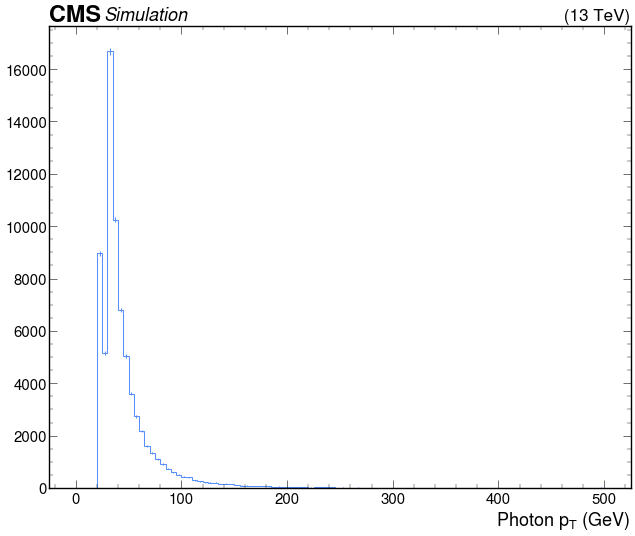

In [5]:
for j, histogram_name in enumerate(histogram_list):
    try:
        histogram = sum_data_all[histogram_name][channel_name,:]
    except:
        try:
            histogram = sum_data_all[histogram_name][channel_name,::4j,::4j]
        except:  
            continue
    plt.figure(figsize=(15, 12))
    utilities.plot(histogram)
    plt.show()
    plt.close()
